In [1]:
import csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

import tensorflow as tf
from tensorflow.keras import layers
import kagglehub

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Kích thước đầu vào của mô hình (cao x rộng). Ảnh gốc là 80 x 60 nên giữ tỉ lệ 3:4.
IMG_H, IMG_W = 96, 72

d:\môn học ở neu\ngành AI\AI66B-Deep-Neural-Network-project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Đường dẫn đến file npz chính xác dựa theo thư mục "Data preprocessing" bên trái màn hình của bạn
d = np.load("Data preprocessing/fashion_96x72.npz", allow_pickle=True)

X_train, y_train = d["X_train"], d["y_train"]
X_val,   y_val   = d["X_val"],   d["y_val"]
X_test,  y_test  = d["X_test"],  d["y_test"]
class_names = list(d["class_names"])
NUM_CLASSES = len(class_names)

print("Load dữ liệu thành công!")
print(f"X_train shape: {X_train.shape}")
print(f"Số lượng lớp: {NUM_CLASSES}")

Load dữ liệu thành công!
X_train shape: (16364, 96, 72, 3)
Số lượng lớp: 10


In [5]:
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_dict = dict(enumerate(class_weights))
print("Class weights đã tính cho các lớp:", class_weights_dict)

Class weights đã tính cho các lớp: {0: np.float64(0.8214859437751004), 1: np.float64(2.552886115444618), 2: np.float64(1.3293257514216084), 3: np.float64(1.767170626349892), 4: np.float64(3.8413145539906104), 5: np.float64(1.2675445391169635), 6: np.float64(0.7269657929808974), 7: np.float64(1.1483508771929825), 8: np.float64(1.327169505271695), 9: np.float64(0.3307194826192401)}


In [7]:
model = tf.keras.Sequential([
    layers.Input(shape=(IMG_H, IMG_W, 3)),
    layers.Rescaling(1./255), # Chuẩn hóa pixel về khoảng [0, 1]
    
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation='softmax')
], name ="simple_cnn_model")

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "simple_cnn_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 96, 72, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 48, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 36, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 18, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 9, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 13824)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,769,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,864,138 (7.11 MB)

 Trainable params: 1,864,138 (7.11 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint('best_simple_cnn.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
]

In [9]:
EPOCHS = 20
BATCH_SIZE = 32

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights_dict, # Tận dụng trọng số lớp đã tính ở cell 5
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step - accuracy: 0.6453 - loss: 0.8492
Epoch 1: val_accuracy improved from None to 0.79099, saving model to best_simple_cnn.keras

Epoch 1: finished saving model to best_simple_cnn.keras
512/512 ━━━━━━━━━━━━━━━━━━━━ 155s 269ms/step - accuracy: 0.6453 - loss: 0.8492 - val_accuracy: 0.7910 - val_loss: 0.5448
Epoch 2/20
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.7958 - loss: 0.4564
Epoch 2: val_accuracy improved from 0.79099 to 0.83547, saving model to best_simple_cnn.keras

Epoch 2: finished saving model to best_simple_cnn.keras
512/512 ━━━━━━━━━━━━━━━━━━━━ 94s 180ms/step - accuracy: 0.7958 - loss: 0.4564 - val_accuracy: 0.8355 - val_loss: 0.4272
Epoch 3/20
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.8277 - loss: 0.3582
Epoch 3: val_accuracy improved from 0.83547 to 0.83604, saving model to best_simple_cnn.keras

Epoch 3: finished saving model to best_simple_cnn.keras
512/512 ━━━━━━━━━━━━━━━━━━━━ 126s 246ms/step 

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ===
Test Loss:     0.3786
Test Accuracy: 89.34%

110/110 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step
=== BÁO CÁO CHI TIẾT (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

Casual Shoes       0.87      0.81      0.84       427
  Flip Flops       0.94      0.93      0.94       137
    Handbags       1.00      0.98      0.99       264
       Heels       0.92      0.96      0.94       198
       Jeans       0.99      0.99      0.99        91
      Kurtas       0.97      0.94      0.95       277
      Shirts       0.91      0.91      0.91       482
Sports Shoes       0.79      0.85      0.82       306
        Tops       0.64      0.89      0.74       265
     Tshirts       0.96      0.87      0.91      1060

    accuracy                           0.89      3507
   macro avg       0.90      0.91      0.90      3507
weighted avg       0.90      0.89      0.90      3507



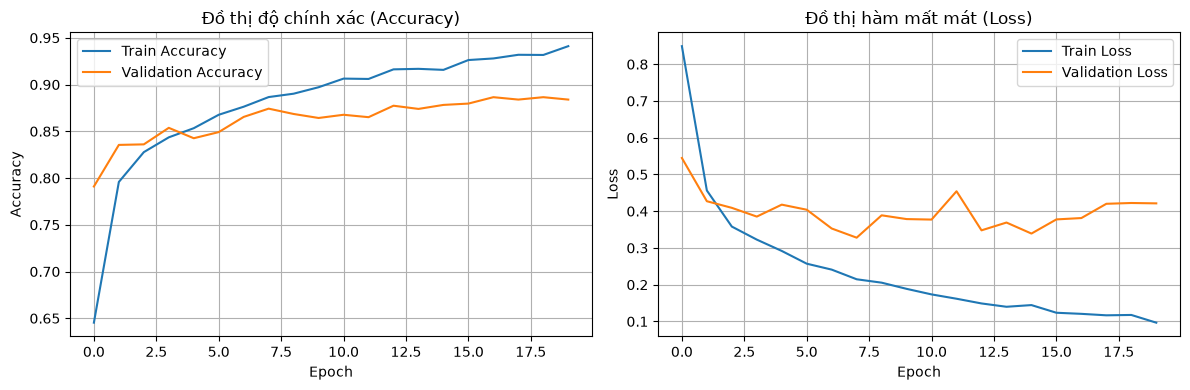

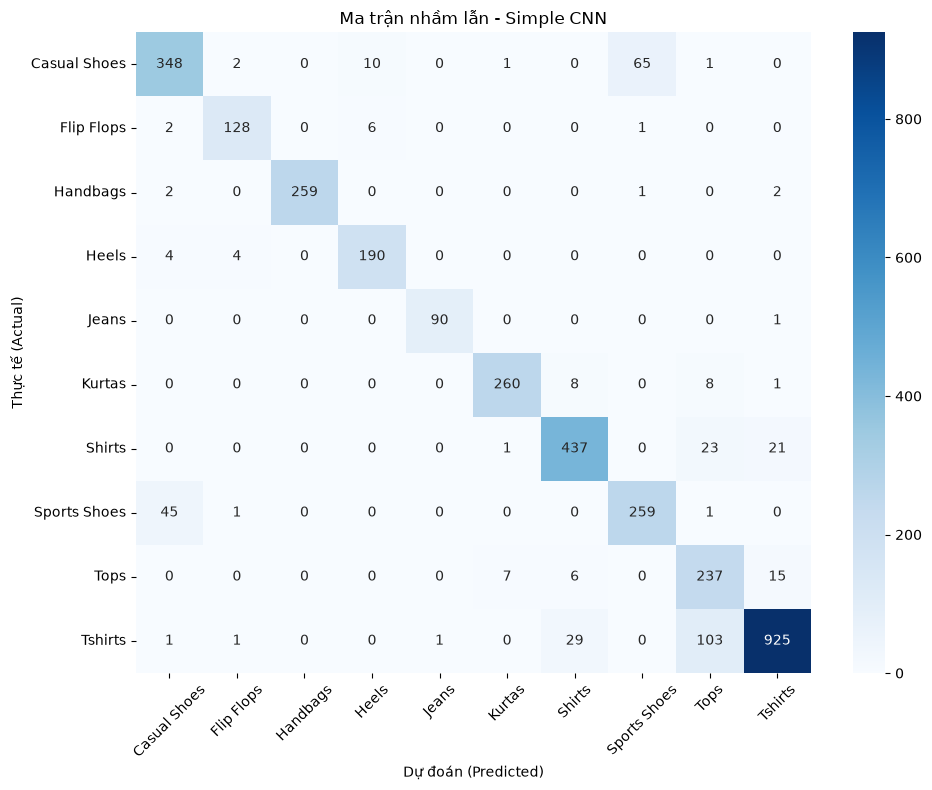

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Đánh giá tổng quan trên tập Test
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ===")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%\n")

# 2. Dự đoán trên tập test để lấy các chỉ số chi tiết
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. In bảng báo cáo chi tiết (Precision, Recall, F1-Score cho từng lớp)
print("=== BÁO CÁO CHI TIẾT (CLASSIFICATION REPORT) ===")
print(classification_report(y_test, y_pred, target_names=class_names))

# 4. Vẽ biểu đồ Lịch sử huấn luyện (Accuracy & Loss qua từng Epoch)
plt.figure(figsize=(12, 4))

# Biểu đồ Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Đồ thị độ chính xác (Accuracy)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Biểu đồ Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Đồ thị hàm mất mát (Loss)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 5. Vẽ Confusion Matrix (Ma trận nhầm lẫn)
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.title('Ma trận nhầm lẫn - Simple CNN')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
# 1. Nạp mô hình CNN đơn giản từ file đã lưu
loaded_model = tf.keras.models.load_model("best_simple_cnn.keras")
print("Đã tải mô hình simple CNN thành công!")

# Kích thước ảnh chuẩn lúc train
IMG_H, IMG_W = 96, 72  

class_names = ['Casual Shoes', 'Flip Flops', 'Handbags', 'Heels', 'Jeans', 'Kurtas', 'Shirts', 'Sports Shoes', 'Tops', 'Tshirts']

# 2. Hàm dự đoán cho MỘT ảnh mới
def predict_image(path, model=loaded_model, top=3):
    with Image.open(path) as im:
        # Chuyển đổi sang RGB, resize về (IMG_W, IMG_H), ép kiểu uint8 và thêm chiều batch [None]
        x = np.asarray(im.convert("RGB").resize((IMG_W, IMG_H)), dtype="uint8")[None]
        
        # Dự đoán xác suất
        p = model.predict(x, verbose=0)[0]
        
        print(f"\nDự đoán cho ảnh: {path}")
        # Sắp xếp và in ra top kết quả có xác suất cao nhất
        for i in p.argsort()[::-1][:top]:
            print(f"  {class_names[i]:<14} {p[i]*100:5.1f}%")

# 3. Gọi hàm dự đoán với file ảnh của bạn
predict_image("image_test.jpg")

Đã tải mô hình simple CNN thành công!

Dự đoán cho ảnh: image_test.jpg
  Tshirts         93.4%
  Tops             5.6%
  Shirts           0.4%


In [8]:
loaded_model.summary()

Model: "simple_cnn_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 96, 72, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 48, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 36, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 18, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 9, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 13824)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,769,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,592,416 (21.33 MB)

 Trainable params: 1,864,138 (7.11 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,728,278 (14.22 MB)